# E — Kiểm chứng cuối và lựa chọn mô hình triển khai

**Vị trí trong tiến trình nghiên cứu:** notebook **C** chọn Front-End **C4/s44** trên V1 bằng khảo sát tổ hợp; notebook **D** đánh giá lượng tử hóa và kiểm thử tĩnh ba checkpoint trên ESP32-S3. Notebook **E** là bước **kiểm chứng và chốt nguyên mẫu**, không mở thêm vòng tìm kiếm mô hình:

- **E1–E3:** hậu kiểm lựa chọn bỏ pre-emphasis bằng F0/Pre0 trên 7 seed (40–46), đáp ứng DSP và các cặp bật/tắt pre.
- **E4a–E4b:** lưu bằng chứng kiến trúc V2/C4 bổ sung để truy vết, không dùng V2 làm đối chứng deploy chính.
- **E4c:** đối chiếu **V1/C4/s44/QAT INT8** và **V3/C4/PTQ INT8** trên ESP32-S3, theo hai log thật.
- **E5:** tổng hợp **Front-End → Quantization → kiến trúc → mô hình triển khai cuối**.

**Nguồn:** dữ liệu FP32 được đọc trực tiếp từ `results/val_summary.csv` và `results/test_summary.csv`; dữ liệu lượng tử V2 được đọc từ `results/D_Quantization_V2_Architecture/`; dữ liệu lượng tử V1 nằm trong **D**; hai log cùng thư mục với notebook ở [`log/C4_QAT.log`](log/C4_QAT.log) và [`log/V3_C4_PTQ.log`](log/V3_C4_PTQ.log). Log chỉ đo **12 tensor tĩnh, 36 lần Invoke mỗi model**, chưa bao gồm thu âm microphone hoặc DSP. Historical Test 159 WAV đã được tham khảo trong quá trình phát triển, **không phải tập kiểm chứng bệnh nhân ngoài nghiên cứu**.


## E0. Ma trận từ C và quy ước

| Cấu hình | α | Mel | FFT | Nhánh |
|---|---:|---:|---:|---|
| F0 | 0,97 | 64 | 1024 | Có pre — tham chiếu lịch sử |
| Pre0 | 0 | 64 | 1024 | Không pre |
| Mel40 | 0,97 | 40 | 1024 | Có pre |
| FFT2048 | 0,97 | 64 | 2048 | Có pre |
| C1 | 0 | 40 | 1024 | Không pre |
| C2 | 0 | 64 | 2048 | Không pre |
| C3 | 0,97 | 40 | 2048 | Có pre |
| C4 | 0 | 40 | 2048 | Không pre — ứng viên cuối |

Giữ architecture V1, preprocessing và protocol chia dữ liệu theo Patient ID của C. **Pre0 nghĩa là `α=0`, không phải bật pre-emphasis.** Hai nhóm được phân lại theo quyết định thiết kế *sau khi có kết quả*; không viết lại lịch sử Phase 2 dùng F0.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Có thể chạy từ thư mục notebook hoặc từ root dự án.
def find_frontend_root():
    bases = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for base in bases:
        for candidate in (
            base,
            base / 'Frontend_Benchmarking',
            base / 'Experiments_Benchmarking' / 'Patient_Node' / 'Frontend_Benchmarking',
        ):
            if (candidate / 'results' / 'val_summary.csv').is_file():
                return candidate.resolve()
    return None

FRONTEND_ROOT = find_frontend_root()
if FRONTEND_ROOT is None:
    raise FileNotFoundError('Không xác định được Frontend_Benchmarking từ thư mục chạy hiện tại.')
CWD = Path.cwd().resolve()
NOTEBOOK_DIR = FRONTEND_ROOT / 'Notebook' / '06_Final_Verifycation'

VARIANT_NAMES = {
    'F0':'F0', 'pre_0':'Pre0', 'mel_40':'Mel40', 'fft_2048':'FFT2048',
    'combo_pre0_mel40':'C1', 'combo_pre0_fft2048':'C2',
    'combo_mel40_fft2048':'C3', 'combo_pre0_mel40_fft2048':'C4',
}
base_trials = {f'{variant}__V1__s{seed}' for variant in VARIANT_NAMES for seed in (42,43,44)}
extra_trials = {f'{variant}__V1__s{seed}' for variant in ('F0','pre_0') for seed in (40,41,45,46)}
v2_trials = {'combo_pre0_mel40_fft2048__V2__s44'}
expected_trials = base_trials | extra_trials | v2_trials

frames = []
for split in ('val', 'test'):
    summary_path = FRONTEND_ROOT / 'results' / f'{split}_summary.csv'
    if not summary_path.is_file():
        raise FileNotFoundError(f'Thiếu summary: {summary_path}')
    frame = pd.read_csv(summary_path, encoding='utf-8-sig')
    frame = frame[frame.trial_id.isin(expected_trials)].copy()
    missing = expected_trials - set(frame.trial_id)
    if missing:
        raise RuntimeError(f'{summary_path.name} thiếu trial: {sorted(missing)}')
    frame['split'] = split
    frame['configuration'] = frame.variant_id.map(VARIANT_NAMES)
    frame['source_file'] = f'results/{split}_summary.csv'
    frame['source_kind'] = 'pipeline CSV chính'
    frames.append(frame)
DATA = pd.concat(frames, ignore_index=True, sort=False)
required = {'trial_id','split','variant_id','architecture','seed','configuration','accuracy',
            'macro_f1','asthma_recall','asthma_fn','non_asthma_fp','source_file'}
assert required.issubset(DATA.columns), sorted(required-set(DATA.columns))
assert DATA.duplicated(['trial_id','split']).sum() == 0
assert DATA.architecture.isin(['V1','V2']).all()
assert set(DATA.split) == {'val','test'}
assert len(DATA) == 66, 'Evidence dự kiến: 24×2 gốc + 8×2 F0/Pre0 mở rộng + V2×2 = 66 dòng'
print('Nguồn FP32: results/val_summary.csv và results/test_summary.csv')
print('Tổng số dòng:', len(DATA))
display(DATA.groupby(['architecture','configuration','split']).agg(n=('seed','count')).reset_index())

Nguồn FP32: results/val_summary.csv và results/test_summary.csv
Tổng số dòng: 66


,architecture,configuration,split,n
0,V1,C1,test,3
1,V1,C1,val,3
2,V1,C2,test,3
3,V1,C2,val,3
4,V1,C3,test,3
5,V1,C3,val,3
6,V1,C4,test,3
7,V1,C4,val,3
8,V1,F0,test,7
9,V1,F0,val,7


## E1. Kiểm tra độ đầy đủ và nguồn gốc dữ liệu

- V1: 8 cấu hình × s42–44 × Val/Test = **48 dòng**.
- V1: F0 và Pre0 × s40–41, s45–46 × Val/Test = **16 dòng mở rộng**, đều đọc trực tiếp từ `results/`.
- V2: C4/s44 × Val/Test = **2 dòng FP32 thăm dò**.

Dữ liệu của D lượng tử hóa **không** thuộc tập 66 dòng FP32 này. Chỉ phân tích trên các file có nguồn đã nêu; không tính xem 12 WAV static từ ESP32-S3 là Test phân loại độc lập.


In [2]:
base = DATA[(DATA.architecture == 'V1') & DATA.seed.isin([42,43,44])].copy()
extra = DATA[(DATA.architecture == 'V1') & DATA.seed.isin([40,41,45,46])].copy()
v2 = DATA[DATA.architecture == 'V2'].copy()
assert len(base) == 48 and len(extra) == 16 and len(v2) == 2
assert set(extra.configuration) == {'F0','Pre0'}
assert set(extra.seed) == {40,41,45,46}
assert all(DATA.groupby(['trial_id']).split.nunique() == 2)
assert all(DATA.loc[DATA.split == 'val', 'asthma_count'] == 38)
assert all(DATA.loc[DATA.split == 'test', 'asthma_count'] == 38)
print('PASS: số lượng theo thiết kế; toàn bộ trial có đủ Val/Test.')
display(extra[['trial_id','split','accuracy','asthma_recall','macro_f1','asthma_fn','non_asthma_fp','source_file']].sort_values(['trial_id','split']))

PASS: số lượng theo thiết kế; toàn bộ trial có đủ Val/Test.


,trial_id,split,accuracy,asthma_recall,macro_f1,asthma_fn,non_asthma_fp,source_file
62,F0__V1__s40,test,0.880503,0.842105,0.845117,6,13,results/test_summary.csv
29,F0__V1__s40,val,0.980519,1.000000,0.974462,0,3,results/val_summary.csv
63,F0__V1__s41,test,0.899371,0.894737,0.870574,4,12,results/test_summary.csv
30,F0__V1__s41,val,0.980519,1.000000,0.974462,0,3,results/val_summary.csv
60,F0__V1__s45,test,0.905660,0.921053,0.879576,3,12,results/test_summary.csv
27,F0__V1__s45,val,0.974026,0.973684,0.965663,1,3,results/val_summary.csv
61,F0__V1__s46,test,0.905660,0.894737,0.877724,4,11,results/test_summary.csv
28,F0__V1__s46,val,0.987013,1.000000,0.982832,0,2,results/val_summary.csv
64,pre_0__V1__s40,test,0.918239,0.842105,0.888613,6,7,results/test_summary.csv
31,pre_0__V1__s40,val,0.993506,0.973684,0.991187,1,0,results/val_summary.csv


## E1b. Cơ chế âm học của pre-emphasis và giả thuyết tắt bộ lọc

**Nguồn tham khảo và phạm vi:** Bài báo [*Hybrid deep learning and YAMNet features for asthma diagnosis from respiratory sounds* (Shatat et al., Scientific Reports, 2026)](https://doi.org/10.1038/s41598-026-49247-y) mô tả **pre-emphasis** ở nhánh tạo **MFCC** trong kiến trúc lai MFCC/YAMNet. Đây là **tiền lệ phương pháp**, không phải bằng chứng `α=0,97` tăng chất lượng trong DS-CNN Log-Mel hay bằng chứng rằng tác giả áp dụng cùng bộ lọc cho tất cả nhánh.

### (1) Bộ lọc bù nghiêng phổ tác động thế nào?

Với `fs = 16 kHz`, `y[n] = x[n] − α x[n−1]`; đáp ứng biên độ `|H(f)| = |1 − α exp(−j2πf/fs)|`. Khi `α=0,97`, **tần số thấp bị suy giảm biên độ mạnh hơn tần số cao**. `α=0` tương đương **bypass** `y[n]=x[n]`. Đây là thay đổi phổ **tương đối**; không được nói nó xóa các thành phần wheeze, khuếch đại tuyệt đối mọi tần số cao hoặc tự động cải thiện SNR.

### (2) Tại sao đáng thử α = 0 cho âm thanh hô hấp?

Âm thanh phổi và **wheeze** có nhiều thành phần ở miền thấp–trung, đôi khi có họa âm cao hơn. Hệ thống đang dùng bandpass 100–2000 Hz và DS-CNN nhận trực tiếp **Log-Mel theo thời gian–tần số**. Mạng có thể học quan hệ phổ trên biểu diễn này mà không bắt buộc phải ấn định bộ lọc nghiêng phổ α=0,97. Ngược lại, pre-emphasis có thể thay đổi tương quan năng lượng giữa các dải và tăng độ nổi bật **tương đối** của các nhiễu cao tần còn trong passband. Đây là **giả thuyết âm học**, không phải chứng minh tác hại đối với mọi mẫu asthma.

### (3) Phân biệt MFCC, Δ/Δ² và Log-Mel

MFCC lấy **DCT từ log năng lượng Mel**, thường nén số hệ số; Δ và Δ² biểu diễn **biến thiên theo thời gian**, không phải phép bù độ dốc phổ. **Pre-emphasis có thể xuất hiện ở cả MFCC lẫn Log-Mel**, không phải yêu cầu bắt buộc của MFCC. Log-Mel giữ trục Mel liền kề cho DS-CNN học cục bộ; ảnh STFT ba chiều chỉ là cách hiển thị lại năng lượng phổ, không thêm thông tin độc lập cho đầu vào mạng.

**Chuyển từ lý thuyết sang kiểm chứng:** Quan sát `F0↔Pre0` cùng **bảy seed** ở E2; so **4 cặp bật/tắt pre** trên **ba seed chung** ở E3; sau đó kiểm tra tương tác với lượng tử hóa ở D. Nếu cấu hình không pre được ưu tiên thì đó là **quyết định thiết kế có điều kiện theo dữ liệu, model và phần cứng**, không phải quy luật sinh lý bệnh hay kết luận rằng pre luôn vô ích.


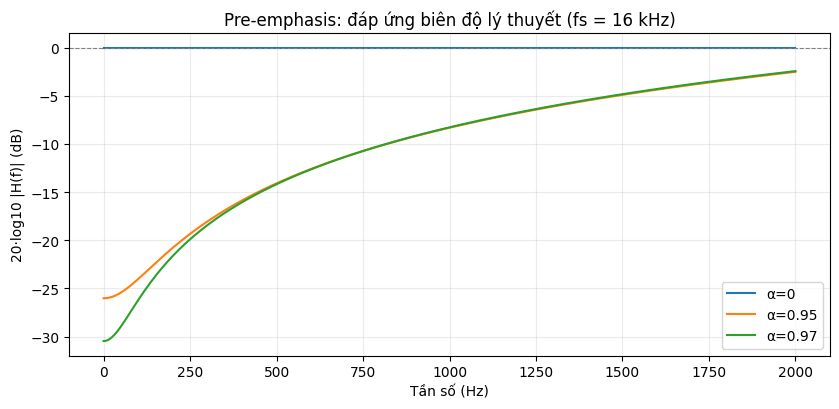

,f_hz,alpha_097_db
0,100,-26.21
1,200,-21.62
2,500,-14.18
3,1000,-8.28
4,2000,-2.45


In [3]:
# Minh họa đáp ứng lý thuyết pre-emphasis, không phải dữ liệu phân loại.
fs = 16_000
freq_hz = np.linspace(0, 2_000, 501)
alpha_values = [0.0, 0.95, 0.97]
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for alpha in alpha_values:
    magnitude = np.abs(1 - alpha * np.exp(-1j * 2 * np.pi * freq_hz / fs))
    db = 20 * np.log10(np.maximum(magnitude, 1e-12))
    ax.plot(freq_hz, db, label=f'α={alpha:g}')
ax.set(xlabel='Tần số (Hz)', ylabel='20·log10 |H(f)| (dB)',
       title='Pre-emphasis: đáp ứng biên độ lý thuyết (fs = 16 kHz)')
ax.axhline(0, color='gray', ls='--', lw=.8)
ax.grid(alpha=.25)
ax.legend()
plt.tight_layout()
plt.show()
probe = np.array([100, 200, 500, 1000, 2000])
mag = np.abs(1 - .97 * np.exp(-1j * 2 * np.pi * probe / fs))
display(pd.DataFrame({'f_hz':probe,'alpha_097_db':np.round(20*np.log10(mag),2)}))

## E2. F0 ↔ Pre0 trên 7 seed: tái lập Accuracy, Macro F1, Recall

So sánh **cùng bảy seed 40–46** trên kiến trúc V1 và cùng Mel64/FFT1024, chỉ khác `α=0,97` (F0) hoặc `α=0` (Pre0). SD là độ lệch chuẩn mẫu (`ddof=1`) qua các lần train, **không phải** biến thiên do bệnh nhân, nguồn ghi âm hoặc môi trường triển khai. Bảng và hình dưới đây được tính từ dữ liệu FP32 đã ghép ở E0–E1; phần nhận xét phân biệt **độ ổn định theo seed** với **chất lượng tổng quát hóa**.

### Test Accuracy của 7 seed (%)

configuration,F0,Pre0
seed,,
40,88.05,91.82
41,89.94,90.57
42,89.31,91.19
43,94.34,91.19
44,91.19,91.82
45,90.57,91.19
46,90.57,89.94


### FP32 — Mean, SD và các chỉ số theo lớp

,split,configuration,n_seed,mean_acc,sd_acc,worst_acc,best_acc,mean_macro_f1,sd_macro_f1,mean_asthma_recall,mean_fn,mean_fp
0,test,F0,7,90.566,1.955,88.050,94.340,87.849,2.417,90.226,3.714286,11.285714
1,test,Pre0,7,91.105,0.672,89.937,91.824,88.475,0.660,90.602,3.571429,10.571429
2,val,F0,7,97.681,1.792,94.156,100.000,96.984,2.272,98.872,0.428571,3.142857
3,val,Pre0,7,98.052,1.500,96.104,99.351,97.451,1.938,98.872,0.428571,2.571429


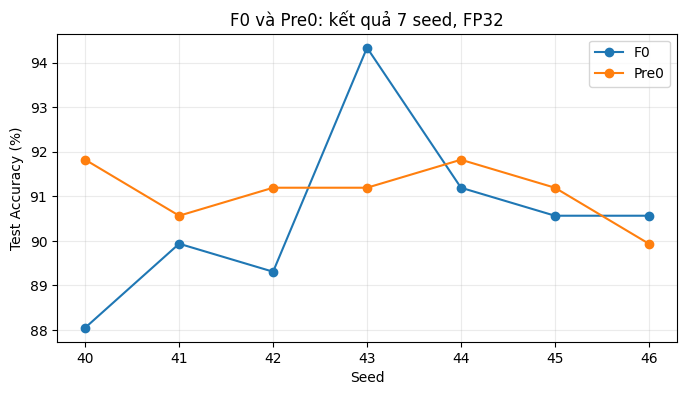

In [4]:
seven = DATA[(DATA.architecture == 'V1') & DATA.configuration.isin(['F0','Pre0'])].copy()
assert len(seven) == 28
assert set(seven.seed) == set(range(40, 47))
assert seven.groupby(['configuration','split']).seed.nunique().eq(7).all()
acc_pivot = seven[seven.split == 'test'].pivot(index='seed',columns='configuration',values='accuracy').sort_index()
display(Markdown('### Test Accuracy của 7 seed (%)'))
display((acc_pivot[['F0','Pre0']]*100).round(2))
stat7 = (seven.groupby(['split','configuration']).agg(
    n_seed=('seed','nunique'),mean_acc=('accuracy','mean'),sd_acc=('accuracy','std'),
    worst_acc=('accuracy','min'),best_acc=('accuracy','max'),
    mean_macro_f1=('macro_f1','mean'),sd_macro_f1=('macro_f1','std'),
    mean_asthma_recall=('asthma_recall','mean'),mean_fn=('asthma_fn','mean'),
    mean_fp=('non_asthma_fp','mean')).reset_index())
for name in ['mean_acc','sd_acc','worst_acc','best_acc','mean_macro_f1','sd_macro_f1','mean_asthma_recall']:
    stat7[name] = (stat7[name]*100).round(3)
display(Markdown('### FP32 — Mean, SD và các chỉ số theo lớp'))
display(stat7)
fig,ax=plt.subplots(figsize=(8,4))
for variant in ['F0','Pre0']:
    ax.plot(acc_pivot.index,acc_pivot[variant]*100,marker='o',label=variant)
ax.set(xticks=list(acc_pivot.index),xlabel='Seed',ylabel='Test Accuracy (%)',title='F0 và Pre0: kết quả 7 seed, FP32')
ax.grid(alpha=.25);ax.legend();plt.show()

### E2.1 — Nhận xét về độ nhạy seed và vai trò của Pre0

Qua **7 seed (40–46)**, Test Accuracy FP32 của **F0 = 90,566% ± 1,955 pp**, trong khi **Pre0 = 91,105% ± 0,672 pp** (*Mean ± SD mẫu*). Biên độ giữa seed cao nhất và thấp nhất tương ứng **6,29 pp** (F0: 88,05–94,34%) và **1,89 pp** (Pre0: 89,94–91,82%). Test Macro F1 của Pre0 cũng ít biến thiên hơn (**SD 0,660 pp** so với **2,417 pp** của F0), còn Test Asthma Recall trung bình gần nhau (**90,602%** và **90,226%**). Trên Validation, cả hai đều đạt Accuracy trung bình cao (Pre0 **98,052%**, F0 **97,681%**).

**Diễn giải:** Trong **bảy lần khởi tạo được kiểm tra**, F0 thể hiện độ nhạy với seed lớn hơn Pre0. Việc bỏ pre-emphasis **không làm suy giảm Accuracy trung bình quan sát được** trong phép đối chứng này, đồng thời Pre0 có độ phân tán Test thấp hơn. Tuy nhiên, chỉ có 7 seed nên **không kết luận pre-emphasis là nguyên nhân duy nhất khiến mọi model kém ổn định**, cũng không coi đây là bằng chứng về bệnh nhân hoặc nguồn ghi mới. F0 vẫn có seed riêng lẻ đạt Test Accuracy cao hơn Pre0 (ví dụ s43), nên kết luận dựa trên **phân bố nhiều seed**, không chọn một điểm cực đại.

**Pre0 không phải cấu hình triển khai cuối:** Pre0 chỉ là F0 bỏ pre (`Mel64`, `FFT1024`), nhằm **cô lập tác động của pre-emphasis**. C4 (`pre=0`, `Mel40`, `FFT2048`) còn là kết quả của khảo sát tương tác Mel/FFT ở C và lượng tử hóa ở D. Do đó, bằng chứng E2 củng cố quyết định **không bắt buộc dùng pre-emphasis**, còn lựa chọn **C4/s44** phải được bảo vệ bằng toàn bộ kết quả C → D → E.

## E3. Kiểm chứng theo cặp yếu tố pre-emphasis trong C (chung 3 seed)

Các cặp **F0→Pre0, Mel40→C1, FFT2048→C2, C3→C4** giữ nguyên Mel, FFT và seed, chỉ thay `α=0,97` thành `α=0`. `Δ = tắt − bật` tính bằng điểm phần trăm. Đây là mô tả 3 seed **FP32**; D thực hiện so sánh lại dưới PTQ/QAT INT8, có thể cho xu hướng khác.


In [5]:
PAIRS=[('F0','Pre0'),('Mel40','C1'),('FFT2048','C2'),('C3','C4')]
paired=[]
for split in ['val','test']:
    q=base[base.split==split].pivot(index='seed',columns='configuration',values=['accuracy','macro_f1','asthma_recall'])
    for enabled,disabled in PAIRS:
        for metric in ['accuracy','macro_f1','asthma_recall']:
            delta=(q[(metric,disabled)]-q[(metric,enabled)])*100
            paired.append({'split':split,'pair':f'{enabled} → {disabled}', 'metric':metric,
                           'delta_mean_pp':delta.mean(),'delta_sd_pp':delta.std(),
                           'n_seed':len(delta)})
PAIRED = pd.DataFrame(paired)
display(PAIRED.round(3))
summary8=base.groupby(['split','configuration']).agg(accuracy_mean=('accuracy','mean'),accuracy_sd=('accuracy','std'),
    asthma_recall_mean=('asthma_recall','mean'),macro_f1_mean=('macro_f1','mean')).reset_index()
summary8['nhanh_pre'] = summary8.configuration.isin(['F0','Mel40','FFT2048','C3']).map({True:'Có pre (α=0,97)',False:'Không pre (α=0)'})
display(Markdown('### 8 cấu hình: chia hai nhánh, cùng 3 seed'))
display(summary8.sort_values(['split','nhanh_pre','accuracy_mean'], ascending=[True,True,False]).round(4))

,split,pair,metric,delta_mean_pp,delta_sd_pp,n_seed
0,val,F0 → Pre0,accuracy,0.000,1.718,3
1,val,F0 → Pre0,macro_f1,-0.049,2.193,3
2,val,F0 → Pre0,asthma_recall,0.000,2.632,3
3,val,Mel40 → C1,accuracy,1.732,2.703,3
4,val,Mel40 → C1,macro_f1,2.243,3.479,3
5,val,Mel40 → C1,asthma_recall,1.754,3.039,3
6,val,FFT2048 → C2,accuracy,0.433,0.992,3
7,val,FFT2048 → C2,macro_f1,0.573,1.254,3
8,val,FFT2048 → C2,asthma_recall,0.877,1.519,3
9,val,C3 → C4,accuracy,0.866,0.375,3


### 8 cấu hình: chia hai nhánh, cùng 3 seed

,split,configuration,accuracy_mean,accuracy_sd,asthma_recall_mean,macro_f1_mean,nhanh_pre
5,test,FFT2048,0.9224,0.0221,0.9123,0.8987,"Có pre (α=0,97)"
4,test,F0,0.9161,0.0254,0.9211,0.8922,"Có pre (α=0,97)"
2,test,C3,0.9015,0.0073,0.8860,0.8723,"Có pre (α=0,97)"
6,test,Mel40,0.8763,0.0419,0.8684,0.8440,"Có pre (α=0,97)"
3,test,C4,0.9161,0.0131,0.8596,0.8870,Không pre (α=0)
7,test,Pre0,0.9140,0.0036,0.9123,0.8886,Không pre (α=0)
0,test,C1,0.9015,0.0131,0.8860,0.8724,Không pre (α=0)
1,test,C2,0.8952,0.0254,0.9123,0.8677,Không pre (α=0)
10,val,C3,0.9719,0.0099,1.0000,0.9636,"Có pre (α=0,97)"
12,val,F0,0.9719,0.0293,0.9825,0.9638,"Có pre (α=0,97)"


## E4a. Kiểm tra tương tác kiến trúc ban đầu: V1/C4 so với V2/C4 FP32

V2/C4 từng được thử bổ sung ở seed 44 để kiểm tra rằng thứ hạng kiến trúc ban đầu trên F0 **có thể thay đổi** khi chuyển sang C4. Kết quả V2 FP32 không đủ để lựa chọn model nhúng. Phép đo quyết định khả năng vận hành cuối của nguyên mẫu sẽ là **V1/QAT ↔ V3/PTQ trên ESP32-S3** ở phần E4c. Đây là kiểm chứng *sau* khi khảo sát Front-End, không phải một bước OFAT.

In [6]:
arch=DATA[(DATA.configuration=='C4') & DATA.seed.eq(44) & DATA.architecture.isin(['V1','V2'])].copy()
assert len(arch)==4
cols=['architecture','split','accuracy','macro_f1','asthma_recall','asthma_fn','non_asthma_fp','parameter_count']
display(arch[cols].sort_values(['split','architecture']).reset_index(drop=True))
for split in ['val','test']:
    frame=arch.set_index(['split','architecture'])
    d=frame.loc[(split,'V2'),'accuracy']-frame.loc[(split,'V1'),'accuracy']
    print(f'{split.upper()}: V2 − V1 = {d*100:+.3f} pp Accuracy')

,architecture,split,accuracy,macro_f1,asthma_recall,asthma_fn,non_asthma_fp,parameter_count
0,V1,test,0.905660,0.869136,0.789474,8,7,331386
1,V2,test,0.918239,0.888613,0.842105,6,7,7802
2,V1,val,0.987013,0.982832,1.000000,0,2,331386
3,V2,val,0.974026,0.965663,0.973684,1,3,7802


VAL: V2 − V1 = -1.299 pp Accuracy
TEST: V2 − V1 = +1.258 pp Accuracy


## E4b. Đối chiếu phụ V2/C4/s44 sau lượng tử hóa (không thuộc so sánh MCU chính)

Bảng này giữ lại các báo cáo V2/C4/s44 đã có, nhằm tránh đánh mất lịch sử thử nghiệm. **V2 không thay thế V3** trong đối chứng ESP32-S3 ở E4c và không được tính vào ma trận 24 checkpoint V1 của C.

**Giới hạn truy vết:** các báo cáo V2 chỉ có tên cấu hình C4/s44; việc gán chúng cho V2 dựa trên CSV FP32 và bối cảnh thử nghiệm, chưa có mã băm (SHA-256) model để xác minh danh tính artifact tuyệt đối.


In [7]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown
quant_root = FRONTEND_ROOT / 'results' / 'D_Quantization_V2_Architecture'
quant_sources = {
    'val': quant_root / 'Validation' / 'validation_summary.csv',
    'test': quant_root / 'Test' / 'test_summary.csv',
}
quant_frames = []
for split, path in quant_sources.items():
    if not path.is_file():
        raise FileNotFoundError(f'Thiếu kết quả lượng tử V2: {path}')
    frame = pd.read_csv(path, encoding='utf-8-sig')
    frame = frame[frame.trial_id.eq('combo_pre0_mel40_fft2048__V2__s44')].copy()
    frame['split'] = split
    frame['method'] = frame.method_id.replace({'KERAS_FP32':'FP32'})
    quant_frames.append(frame)
qv2 = pd.concat(quant_frames, ignore_index=True)
order = ['FP32','PTQ_INT8','QAT_INT8','PTQ_INT16x8']
assert len(qv2) == 8 and set(qv2.method) == set(order)
pivot = qv2.pivot(index='method', columns='split', values='accuracy')
v2_test = qv2[qv2.split.eq('test')].set_index('method')
out = pd.DataFrame({
    'Val Acc (%)': [100*pivot.loc[m,'val'] for m in order],
    'Test Acc (%)': [100*pivot.loc[m,'test'] for m in order],
    'Test Asthma Recall (%)':[100*v2_test.loc[m,'asthma_recall'] for m in order],
    'Test Macro F1 (%)':[100*v2_test.loc[m,'macro_f1'] for m in order],
    'Test FN / FP':[f"{int(v2_test.loc[m,'asthma_fn'])} / {int(v2_test.loc[m,'non_asthma_fp'])}" for m in order],
}, index=order)
display(Markdown('### V2/C4/s44: FP32 và ba kiểu lượng tử bổ sung'))
display(out.round(3))
display(Markdown('**Đối chứng V1/C4/s44 QAT INT8 (D):** Val Accuracy **97,403%**, Test Accuracy **95,597%**, Test Asthma Recall **92,105%**, Test FN/FP **3/4**. V2/C4/s44 QAT INT8 có Test Accuracy **91,195%**, Recall **84,211%**, FN/FP **6/8**. Không khẳng định V2 đã profiling trên board.'))


### V2/C4/s44: FP32 và ba kiểu lượng tử bổ sung

,Val Acc (%),Test Acc (%),Test Asthma Recall (%),Test Macro F1 (%),Test FN / FP
FP32,97.403,91.824,84.211,88.861,6 / 7
PTQ_INT8,92.857,88.679,84.211,85.211,6 / 12
QAT_INT8,98.052,91.195,84.211,88.109,6 / 8
PTQ_INT16x8,97.403,91.824,84.211,88.861,6 / 7


**Đối chứng V1/C4/s44 QAT INT8 (D):** Val Accuracy **97,403%**, Test Accuracy **95,597%**, Test Asthma Recall **92,105%**, Test FN/FP **3/4**. V2/C4/s44 QAT INT8 có Test Accuracy **91,195%**, Recall **84,211%**, FN/FP **6/8**. Không khẳng định V2 đã profiling trên board.

## E4c. Kiểm chứng kiến trúc triển khai: V1/QAT so với V3/PTQ trên ESP32-S3

Trên cùng **Front-End C4 và cửa sổ 5 s**, V3 HelloEdge có FP32 Test Accuracy **93,082%**, cao hơn V1/C4/s44 FP32 **90,566%**. Tuy nhiên, lựa chọn cuối phải xét **artifact sau lượng tử hóa, bộ nhớ và thời gian chạy trên ESP32-S3**, không chỉ FP32 Accuracy.

| Tiêu chí | V1/C4/s44/**QAT INT8** | V3/C4/**PTQ INT8** |
|---|---:|---:|
| Historical Test Accuracy | **95,597% (152/159)** | 93,711% (149/159) |
| Test Asthma Recall | 92,105% | 92,105% |
| Test FN / FP | **3 / 4** | 3 / 7 |
| Kích thước model (byte) | 347.968 | **47.448** |
| TensorArena *used* (byte) | **169.380** | 173.188 |
| `Invoke()` trung bình | **1.164,203 ms** | 11.452,180 ms |
| `Invoke()` thành công | 36/36 | 36/36 |
| Raw INT8 exact Python↔ESP | 11/12 | **12/12** |
| Nhãn Python↔ESP | 12/12 | 12/12 |

**Đánh đổi:** V3 có model nhỏ hơn khoảng **86,4%** nhưng thời gian `Invoke()` **lớn hơn ~9,84 lần**; TensorArena used giữa hai model gần tương đương. Với mục tiêu xử lý cửa sổ 5 giây, V1 có lợi thế thời gian suy luận rõ rệt trong đúng điều kiện profiling này. Không suy ra V1 luôn nhanh hơn V3 trên mọi backend hoặc phương pháp lượng tử, vì ở đây đang so **hai phương án triển khai khác nhau (V1/QAT và V3/PTQ)**.

**Danh tính artifact quan trọng:** V1/QAT **347.968 B, Test 95,597%** là bản đã profiling trong D và tại đây. Báo cáo lượng tử hóa V1/QAT khác (**347.960 B, Test 93,082%**) **không phải cùng artifact được xác nhận**; không thay thế file đã đo nếu chưa so SHA-256, checkpoint và recipe. Log không tự chứng minh đầy đủ cấu hình DSP — phần này được nối với hồ sơ train/deploy.

**Đối chiếu log gốc:** [V1 C4/s44 QAT](log/C4_QAT.log) · [V3 C4 PTQ](log/V3_C4_PTQ.log). Cell sau **ưu tiên đọc log tại `Notebook/06_Final_Verifycation/log/`**, chỉ dùng snapshot khi file không hiện diện và phải ghi rõ trạng thái nguồn. `Invoke()` chưa bao gồm thu âm 5 s, Butterworth, STFT hoặc Log-Mel; TensorArena hiện cấp **1 MiB PSRAM**, không đồng nghĩa toàn bộ 1 MiB đã sử dụng.


,model_b,arena_b,latency_ms,success,raw_match,label_match,maxerr_lsb,status,source
candidate,,,,,,,,,
V1 / C4 / s44 / QAT,347968,169380,1164.203,36/36,11/12,12/12,61.0,Đọc từ log,log\C4_QAT.log
V3 / C4 / PTQ,47448,173188,11452.180,36/36,12/12,12/12,0.0,Đọc từ log,log\V3_C4_PTQ.log


V3/V1 Invoke = 9.84x. Chỉ tính Invoke, không gồm capture/DSP.


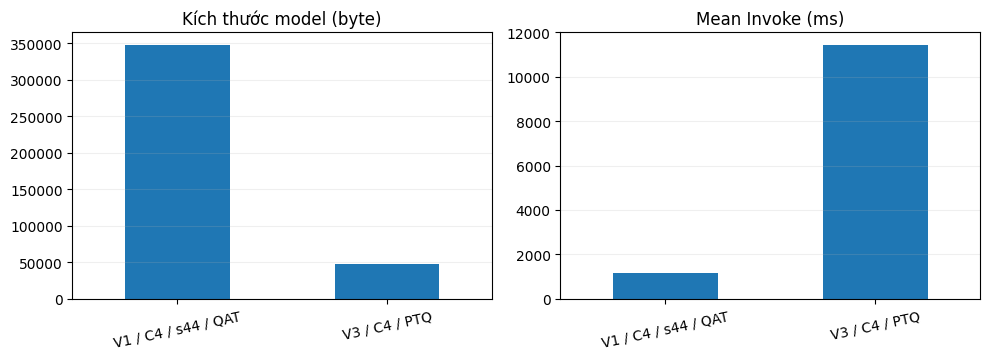

In [8]:
import re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Snapshot giúp đọc lại notebook nếu tách rời khỏi log; KHÔNG xem là phép đo vừa thực hiện.
SNAPSHOT = {
    'V1 / C4 / s44 / QAT': {'model_b':347968,'arena_b':169380,'latency_ms':1164.2035,'raw_match':'11/12','label_match':'12/12','success':'36/36','maxerr_lsb':61},
    'V3 / C4 / PTQ': {'model_b':47448,'arena_b':173188,'latency_ms':11452.18,'raw_match':'12/12','label_match':'12/12','success':'36/36','maxerr_lsb':0},
}
LOGFILES = {
    'V1 / C4 / s44 / QAT': ('C4_QAT.log', 'V1_C4_QAT.log'),
    'V3 / C4 / PTQ': ('V3_C4_PTQ.log',),
}

def find_log(names):
    roots = [NOTEBOOK_DIR, CWD]
    if FRONTEND_ROOT is not None:
        roots += [FRONTEND_ROOT]
    roots += list(CWD.parents)
    candidates = []
    for root in roots:
        for name in names:
            candidates.extend([
                root / 'log' / name,
                root / '06_Final_Verifycation' / 'log' / name,
                root / 'Notebook' / '06_Final_Verifycation' / 'log' / name,
                root / 'Frontend_Benchmarking' / 'Notebook' / '06_Final_Verifycation' / 'log' / name,
                root / 'Phase4_Deployment_Artifacts' / 'Log_Deploy' / name,  # lịch sử
                root / 'AI_Training_Model' / 'Phase4_Deployment_Artifacts' / 'Log_Deploy' / name,
            ])
    return next((p for p in candidates if p.is_file()), None)

def read_stat(s, pattern, cast=float):
    m = re.search(pattern, s, flags=re.I)
    return cast(m.group(1)) if m else None

rows = []
for key, names in LOGFILES.items():
    values = SNAPSHOT[key].copy()
    path = find_log(names)
    if path:
        raw = path.read_text(encoding='utf-8', errors='replace')
        parsed = {
            'model_b': read_stat(raw, r'Model Flash size\s*:\s*(\d+)\s*B', int),
            'arena_b': read_stat(raw, r'Tensor Arena used\s*:\s*(\d+)\s*B', int),
            'latency_ms': read_stat(raw, r'Inference latency avg\s*:\s*[\d.]+\s*us\s*\(([\d.]+)\s*ms\)'),
            'raw_match': read_stat(raw, r'Python/ESP32 INT8 exact\s*:\s*(\d+/\d+)', str),
            'label_match': read_stat(raw, r'Python/ESP32 label match\s*:\s*(\d+/\d+)', str),
            'maxerr_lsb': read_stat(raw, r'Python/ESP32 INT8 maxerr\s*:\s*([\d.]+)\s*LSB'),
        }
        m = re.search(r'Inference count\s*:\s*(\d+)\s*OK\s*/\s*(\d+)\s*failed', raw, re.I)
        parsed['success'] = f'{m.group(1)}/{int(m.group(1)) + int(m.group(2))}' if m else None
        missing = [field for field, v in parsed.items() if v is None]
        if missing:
            raise ValueError(f'Log {path} thiếu trường: {missing}. Không dùng số liệu snapshot để tự điền thiếu.')
        for field, val in parsed.items():
            if field in ('model_b','arena_b','latency_ms') and abs(val-values[field]) > max(1,0.001*values[field]):
                print('LƯU Ý: log khác snapshot:', key, field, val, 'so với', values[field])
            values[field] = val
        expected = 'combo_pre0_mel40_fft2048__V1__s44' if key.startswith('V1') else 'V3_HelloEdge'
        if expected not in raw:
            raise ValueError(f'Log {path.name} không chứa định danh model mong đợi: {expected}')
        try:
            values['source'] = str(path.relative_to(NOTEBOOK_DIR))
        except ValueError:
            values['source'] = str(path)
        values['status'] = 'Đọc từ log'
    else:
        values['source'] = 'Snapshot lưu trong notebook (chưa tìm thấy log)'
        values['status'] = 'CHƯA XÁC MINH LOCAL'
        print(f'CẢNH BÁO: chưa tìm thấy {names[0]} ở 06_Final_Verifycation/log. Đang hiển thị snapshot lịch sử.')
    rows.append({'candidate':key, **values})

BOARD = pd.DataFrame(rows).set_index('candidate')
display(BOARD[['model_b','arena_b','latency_ms','success','raw_match','label_match','maxerr_lsb','status','source']])
ratio = BOARD.loc['V3 / C4 / PTQ','latency_ms'] / BOARD.loc['V1 / C4 / s44 / QAT','latency_ms']
print(f'V3/V1 Invoke = {ratio:.2f}x. Chỉ tính Invoke, không gồm capture/DSP.')
if BOARD.status.ne('Đọc từ log').any():
    print('LƯU Ý: bảng chưa đọc đủ hai file log; không khẳng định đã kiểm chứng log local.')
fig,axes = plt.subplots(1,2,figsize=(10,3.7))
for ax, field, title in [(axes[0],'model_b','Kích thước model (byte)'), (axes[1],'latency_ms','Mean Invoke (ms)')]:
    BOARD[field].plot.bar(ax=ax,legend=False)
    ax.set_title(title)
    ax.set_xlabel('')
    ax.grid(axis='y',alpha=.2)
    ax.tick_params(axis='x', rotation=12)
fig.tight_layout()
plt.show()


## E5. Kết luận cuối và chốt mô hình triển khai

**(1) Front-End C4 và kiểm chứng pre-emphasis:** Sau OFAT (B) và khảo sát tổ hợp 8 × 3 seed (C), E2 bổ sung đối chứng **F0 ↔ Pre0 cùng 7 seed (40–46)** trên V1 với Mel64/FFT1024 cố định. Test Accuracy FP32 đạt **90,566% ± 1,955 pp** (F0) và **91,105% ± 0,672 pp** (Pre0); Macro F1 SD là **2,417** so với **0,660 pp**. Dữ liệu cho thấy **F0 dao động mạnh hơn giữa các seed đã thử**, còn tắt pre-emphasis không làm giảm hiệu năng trung bình quan sát được. Đây là bằng chứng có điều kiện về **độ biến thiên theo seed**, không chứng minh α=0 luôn tốt hơn trong mọi Front-End hoặc trên nguồn ghi mới. **Pre0 chỉ là nhánh cô lập tác động pre-emphasis, không thay thế C4.** Cấu hình **C4** (`pre=0`, `Mel40`, `FFT2048`, `hop=625`, Butterworth `100–2000 Hz`, bậc 5, `5 s/16 kHz`) vẫn được ưu tiên dựa trên khảo sát Mel/FFT và kết quả lượng tử hóa ở C–D; E3 cũng chỉ ra hiệu quả tắt pre có thể tương tác với Mel/FFT.

**(2) Ứng viên lượng tử hóa từ D:** Trong phạm vi **kiến trúc V1**, D đã ưu tiên checkpoint **C4/s44/QAT INT8** (historical Test Accuracy **95,597%**, Asthma Recall **92,105%**, FN/FP **3/4**) và đo tĩnh thành công trên ESP32-S3. Đây là **artifact 347.968 byte đã profiling**, không được đánh đồng với bản QAT khác 347.960 byte/93,082%.

**(3) Chốt kiến trúc trên ESP32-S3:** V3/C4 có FP32 Test Accuracy cao hơn V1/C4 tại seed 44 (**93,082% so với 90,566%**). Tuy nhiên, khi xét **hai artifact triển khai thực tế** V1/QAT và V3/PTQ, V1 đạt `Invoke()` trung bình **1.164,203 ms** so với **11.452,180 ms** của V3 (**V3 chậm ~9,84×**); TensorArena used lần lượt **169.380** và **173.188 byte**. V3 có model nhỏ hơn (**47.448** so với **347.968 byte**) và parity raw tốt hơn (**12/12** so với **11/12**), nhưng **lợi thế kích thước file không bù được chênh lệch thời gian suy luận** cho mục tiêu của nguyên mẫu. Đây là so sánh **V1/QAT ↔ V3/PTQ**, không quy toàn bộ khác biệt cho kiến trúc thuần túy.

**Quyết định cuối:** **V1 / C4 / seed 44 / QAT INT8** là model được chọn cho nguyên mẫu ESP32-S3, căn cứ đồng thời vào hiệu năng sau lượng tử hóa, khả năng tương thích toán tử, bộ nhớ sử dụng và tốc độ `Invoke()` đã đo. Hai log truy vết: [**C4_QAT.log**](log/C4_QAT.log) và [**V3_C4_PTQ.log**](log/V3_C4_PTQ.log). Khi tích hợp firmware, cần xác minh đúng **artifact đã profiling** (tên, kích thước file, lý tưởng là SHA-256), không tự thay bằng bản QAT tái xuất khác.

**Giới hạn:** Hai log đều có **36/36 Invoke thành công và 12/12 nhãn khớp Python–ESP32**, nhưng V1 có một mẫu sai khác raw INT8 tối đa **61 LSB**; TensorArena được cấp **1 MiB PSRAM**, trong khi `used` chỉ là phần TFLM báo sử dụng. Phép đo chỉ trên tensor tĩnh, chưa chứng minh độ trễ toàn pipeline (thu âm + DSP + suy luận), khả năng tổng quát hóa cho nguồn ghi mới hoặc giá trị chẩn đoán y khoa. Từ đây, nghiên cứu **chốt mô hình**, chuyển sang tích hợp và kiểm chứng hệ thống thực tế; không mở thêm vòng lựa chọn Front-End hoặc kiến trúc trong bộ thí nghiệm này.


In [9]:
print('E — FINAL VERIFICATION SUMMARY')
print('C → D → E: Front-End C4 → QAT INT8 / static profiling → kiểm chứng cuối V1/V3.')
print('Model được chọn: V1 / C4 / s44 / QAT INT8; artifact đã profiling: 347968 B.')
print('Dữ liệu đo: Notebook/06_Final_Verifycation/log/C4_QAT.log và V3_C4_PTQ.log.')
print('Giới hạn: chỉ Invoke trên tensor tĩnh; chưa có microphone + DSP end-to-end.')


E — FINAL VERIFICATION SUMMARY
C → D → E: Front-End C4 → QAT INT8 / static profiling → kiểm chứng cuối V1/V3.
Model được chọn: V1 / C4 / s44 / QAT INT8; artifact đã profiling: 347968 B.
Dữ liệu đo: Notebook/06_Final_Verifycation/log/C4_QAT.log và V3_C4_PTQ.log.
Giới hạn: chỉ Invoke trên tensor tĩnh; chưa có microphone + DSP end-to-end.
